In [39]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import lattice
import importlib
import kmc
import loading as ld
importlib.reload(kmc)

<module 'kmc' from '/home/nara/Projetos/programa-tiago/kmc.py'>

In [40]:
RF=1
tau = 1
r0=1
n= 500 
LOAD_FIXED_KAPPA= False
FIXED_KAPPA = 0.476#2/3
save = False
cutoff = r0
krot_dip = 0 #=0 -> no rotation

In [41]:
import shutil
import os
pasta = 'Rounds_pesado'
try: 
    shutil.rmtree(pasta)
except:
    pass

os.makedirs(pasta)

M = 300
nrounds = 10000

n_1D= 500
L_1D =  r0*np.array([n])
PBC_1D = [0]

n_2D = 25
L_2D =  r0*np.array([n,n])
PBC_2D = [0,1]

n_3D = 8
L_3D =  r0*np.array([n,n,n])
PBC_3D = [0,1,2]

In [ ]:
#1D

kappas2_LD = []
for i in range(M):
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L_1D,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n_1D,PBC=PBC_1D,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=6,verbose=1)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L_1D),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

    kappas2 = out_dict['kappa2_D_lis']

    kappas2_LD = [np.mean(kappas2[0:m]) for m in range(5,nrounds)]
    c_1D = np.array(kappas2_LD)
    np.savetxt(f"{pasta}/kappas2_rounds_1D_{i}.txt", c_1D)


In [ ]:
#2D

kappas2_LD = []
for i in range(M):
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L_2D,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n_2D,PBC=PBC_2D,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=6,verbose=1)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L_2D),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

    kappas2 = out_dict['kappa2_D_lis']

    kappas2_LD = [np.mean(kappas2[0:m]) for m in range(5,nrounds)]
    c_2D = np.array(kappas2_LD)
    np.savetxt(f"{pasta}/kappas2_rounds_2D_{i}.txt", c_2D)


In [ ]:
#3D 

kappas2_LD = []
for i in range(M):
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L_3D,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n_3D,PBC=PBC_3D,krot_dip=krot_dip)
    syst.make_lattice()
    results = Parallel(n_jobs=6,verbose=1)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L_3D),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

    kappas2 = out_dict['kappa2_D_lis']

    kappas2_LD = [np.mean(kappas2[0:m]) for m in range(5,nrounds)]
    c_3D = np.array(kappas2_LD)
    np.savetxt(f"{pasta}/kappas2_rounds_3D_{i}.txt", c_3D)


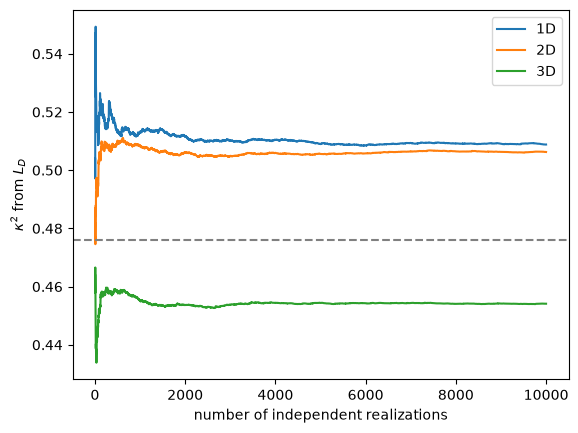

In [49]:
c_1D = np.zeros(nrounds-5)
c_2D = np.zeros(nrounds-5)
c_3D = np.zeros(nrounds-5)
nround_lis = np.arange(5, nrounds)


for i in range(M):
    c_1D += np.loadtxt(f"{pasta}/kappas2_rounds_1D_{i}.txt")
    c_2D += np.loadtxt(f"{pasta}/kappas2_rounds_2D_{i}.txt")
    c_3D += np.loadtxt(f"{pasta}/kappas2_rounds_3D_{i}.txt")
    #c_3D_i = np.loadtxt(f"{pasta}/kappas2_rounds_3D_{i}.txt")
    #plt.plot(nround_lis_3D, c_3D_i)

c_1D = c_1D/M
c_2D = c_2D/M
c_3D = c_3D/M

plt.figure()
plt.plot(nround_lis, c_1D, label = '1D')
plt.plot(nround_lis, c_2D, label = '2D')
plt.plot(nround_lis, c_3D, label = '3D')
plt.axhline(0.476, linestyle = '--', c = 'gray')
plt.xlabel("number of independent realizations")
plt.ylabel(r"$\kappa^2$ from $L_D$")
plt.legend()
plt.savefig('grafico_rounds_pesado.png')
plt.show()